---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---
## Group 29 · MiMHotels
- Naufal Baldemar Ardanni (13521154)
- Theodore Marvel Suranton (10623061)
- Muhammad Zulfiansyah Bayu Pratama (13521028)
- Jingglang Galih Rinenggan (13524095)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

A canceled booking leaves an empty room that could have been sold to another guest. Predicting cancellations early helps Ronaldo Hotel plan overbooking, send reminders and set suitable cancellation policies. This notebook builds five classifiers from scratch and compares them with scikit-learn.

## Aim

Predict `is_canceled` (1 = canceled, 0 = not canceled) for every booking in `test.csv`, using only KNN, a decision tree, logistic regression, SVM and Naive Bayes implemented from scratch.

## Metric

**Macro F1**: the average of the F1-score of the canceled class and the F1-score of the not-canceled class. Both classes count equally, so predicting a single class scores poorly.

## Dataset

`train.csv` holds 27,373 labeled bookings and `test.csv` holds 6,844 unlabeled ones. Each booking describes the guests, the length of stay, the meal package, the room category, the booking channel, the price and the booking history of the guest. Some values are missing.

## Approach

Split the training data, prepare it with statistics from the training split only, train and tune the five models, compare them with scikit-learn, choose the final model by 5-fold cross-validation and write the Kaggle submission.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import random
import runpy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

from ronaldohotel.data.preprocessing import (
    Preprocessor,
    clean_training_data,
    target_array,
)
from ronaldohotel.evaluation.metrics import (
    best_threshold,
    confusion_matrix,
    macro_f1,
    stratified_kfold,
    stratified_split,
)
from ronaldohotel.scratch.decision_tree import DecisionTree
from ronaldohotel.scratch.knn import KNN
from ronaldohotel.scratch.logistic_regression import LogisticRegression
from ronaldohotel.scratch.naive_bayes import NaiveBayes
from ronaldohotel.scratch.svm import SVM

## Settings

Paths and shared constants are kept in this class.

In [3]:
def find_root() -> Path:
    here = Path.cwd().resolve()
    return next(p for p in (here, *here.parents) if (p / "pyproject.toml").exists())


class Settings:
    SEED = 42
    ROOT = find_root()
    DATA_DIR = ROOT / "data"
    OUTPUT_DIR = ROOT / "output"
    GRID = np.linspace(0.05, 0.95, 91)


CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)  # noqa: NPY002


seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / "train.csv", dtype={"id": str})
test_df = pd.read_csv(CFG.DATA_DIR / "test.csv", dtype={"id": str})

print(f"Train: {train_df.shape}  Test: {test_df.shape}")

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
print(train_df.shape, test_df.shape)
display(train_df.dtypes.to_frame("dtype").T)
display(train_df.describe().T[["count", "mean", "min", "50%", "max"]].round(2))

(27373, 19) (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
dtype,str,float64,float64,int64,int64,str,float64,str,float64,int64,int64,int64,str,int64,int64,int64,float64,float64,int64


,count,mean,min,50%,max
num_adults,26564.0,1.85,0.0,2.0,4.0
num_children,24338.0,0.12,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.0,1.0,7.0
weekday_nights,27373.0,2.21,0.0,2.0,17.0
needs_parking,26291.0,0.03,0.0,0.0,1.0
days_before_arrival,26250.0,85.38,0.0,58.0,448.0
arrival_year,27373.0,2023.82,2023.0,2024.0,2024.0
arrival_month,27373.0,7.40,1.0,8.0,12.0
arrival_day,27373.0,15.54,1.0,16.0,31.0
is_returning_guest,27373.0,0.03,0.0,0.0,1.0


## Explore Data

This part covers distributions and relationships between attributes.

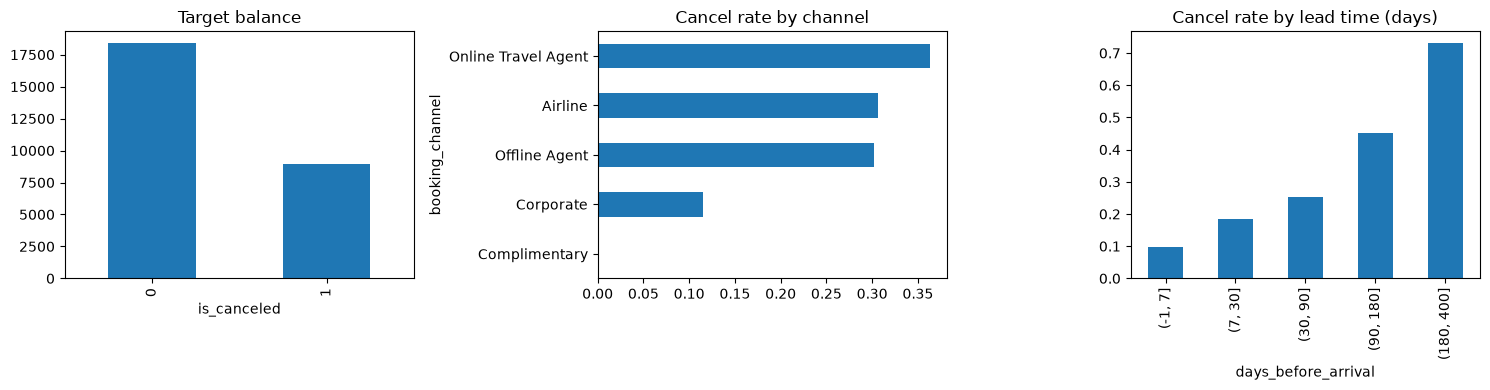

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train_df["is_canceled"].value_counts().sort_index().plot.bar(
    ax=axes[0], title="Target balance"
)
train_df.groupby("booking_channel")["is_canceled"].mean().sort_values().plot.barh(
    ax=axes[1], title="Cancel rate by channel"
)
lead = pd.cut(train_df["days_before_arrival"], [-1, 7, 30, 90, 180, 400])
train_df.groupby(lead, observed=True)["is_canceled"].mean().plot.bar(
    ax=axes[2], title="Cancel rate by lead time (days)"
)
plt.tight_layout()
plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
missing = train_df.isna().mean().mul(100).round(1)
display(missing[missing > 0].to_frame("missing %").T)
print("Exact duplicates (ignoring id):", train_df.drop(columns="id").duplicated().sum())
print(
    "Zero-night stays:",
    ((train_df.weekend_nights + train_df.weekday_nights) == 0).sum(),
)
print("Zero-rate bookings:", (train_df.nightly_rate_idr == 0).sum())

,num_adults,num_children,meal_package,needs_parking,room_category,days_before_arrival,nightly_rate_idr,special_requests
missing %,3.0,11.1,6.4,4.0,3.7,4.1,7.4,9.1


Exact duplicates (ignoring id): 64
Zero-night stays: 64
Zero-rate bookings: 413


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
train_clean = clean_training_data(train_df)
y_all = target_array(train_clean)
fit_idx, val_idx = stratified_split(y_all, val_size=0.2, seed=CFG.SEED)
train_set = train_clean.iloc[fit_idx].reset_index(drop=True)
val_set = train_clean.iloc[val_idx].reset_index(drop=True)
y_train, y_val = target_array(train_set), target_array(val_set)
print(
    f"train_set: {train_set.shape}  val_set: {val_set.shape}  duplicates dropped: {len(train_df) - len(train_clean)}"
)

train_set: (21847, 19)  val_set: (5462, 19)  duplicates dropped: 64


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
features = [c for c in train_set.columns if c not in ("id", "is_canceled")]
print(
    len(features),
    "attributes are kept as inputs. id (identifier) and is_canceled (target) are excluded.",
)

17 attributes are kept as inputs. id (identifier) and is_canceled (target) are excluded.


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
gaps = (
    pd.DataFrame(
        {
            "train %": train_set.isna().mean(),
            "val %": val_set.isna().mean(),
            "test %": test_df.isna().mean(),
        }
    )
    .mul(100)
    .round(1)
)
display(gaps[(gaps > 0).any(axis=1)])

,train %,val %,test %
days_before_arrival,4.0,4.5,4.2
meal_package,6.3,6.9,6.5
needs_parking,3.9,4.2,3.6
nightly_rate_idr,7.1,7.9,7.9
num_adults,3.0,2.9,2.6
num_children,11.2,10.8,10.9
room_category,3.6,3.9,3.5
special_requests,9.3,8.5,8.7


**Insights.** Eight attributes have 3-11% missing values in both the training and the test data. Count-like columns take the most frequent training value, the two continuous columns (`days_before_arrival`, `nightly_rate_idr`) are predicted by a ridge regression on fully observed columns, and missing categories become an explicit `Unknown` level. Each of these columns also gets a 0/1 missing indicator because missingness can carry information. The decision tree keeps the gaps as NaN and sends them to the larger child.

### Duplicates

This part covers repeated records.

In [12]:
print(
    "Duplicates left in train_set:",
    train_set.drop(columns="id").duplicated().sum(),
    "| dropped before the split:",
    len(train_df) - len(train_clean),
)

Duplicates left in train_set: 0 | dropped before the split: 64


**Insights.** Exact duplicate bookings (ignoring `id`) are removed from the training data only, before the split, so identical rows cannot appear in both the training and the validation set. Test rows are never dropped because every `id` needs a prediction.

### Outliers

This part covers values far from the rest of the data.

In [13]:
for col in ["days_before_arrival", "nightly_rate_idr"]:
    q1, q3 = train_set[col].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    print(
        f"{col}: {(train_set[col] > fence).sum()} values above the IQR fence ({fence:,.0f}); max = {train_set[col].max():,.0f}"
    )

days_before_arrival: 741 values above the IQR fence (290); max = 448
nightly_rate_idr: 535 values above the IQR fence (3,052,000); max = 9,165,000


**Insights.** Both columns are strongly right-skewed. Extreme values are real bookings, so none are removed; `log1p` compresses them before standardization, and the decision tree does not depend on scale.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
print("adults == 0:", (train_set.num_adults == 0).sum())
print(
    "zero-night stays:",
    ((train_set.weekend_nights + train_set.weekday_nights) == 0).sum(),
)
display(
    train_set.groupby(train_set.nightly_rate_idr == 0)["is_canceled"]
    .agg(["mean", "size"])
    .rename_axis("zero rate")
)
print(
    "rarest meal packages:", train_set["meal_package"].value_counts().tail(2).to_dict()
)
print(
    "rarest room categories:",
    train_set["room_category"].value_counts().tail(2).to_dict(),
)

adults == 0: 88
zero-night stays: 52


,mean,size
zero rate,,
False,0.332466,21518
True,0.003040,329


rarest meal packages: {'Half Board': 1782, 'Full Board': 4}
rarest room categories: {'Type F': 102, 'Type E': 2}


**Insights.** Zero-rate and zero-night rows follow patterns that also occur in the test data, so they are kept as legitimate records instead of being treated as errors.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [15]:
prep = Preprocessor().fit(train_set)
indicators = [n for n in prep.feature_names_ if n.endswith("_missing")]
print(
    len(indicators), "missing-value indicator attributes are constructed:", indicators
)

8 missing-value indicator attributes are constructed: ['num_adults_missing', 'num_children_missing', 'needs_parking_missing', 'special_requests_missing', 'days_before_arrival_missing', 'nightly_rate_idr_missing', 'meal_package_missing', 'room_category_missing']


**Insights.** Only the missing-value indicators are constructed. Sums such as the total number of nights were not added because the models can combine `weekend_nights` and `weekday_nights` themselves.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
print(
    "log1p is applied to: days_before_arrival, nightly_rate_idr, prior_cancellations, prior_completed_bookings"
)
display(
    pd.DataFrame(
        {"train mean": prep.mean_, "train std": prep.std_},
        index=prep.feature_names_[:12],
    )
    .round(3)
    .T
)

log1p is applied to: days_before_arrival, nightly_rate_idr, prior_cancellations, prior_completed_bookings


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,arrival_year,arrival_month,arrival_day,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
train mean,1.851,0.106,0.819,2.207,3.732,2023.820,7.413,15.575,0.009,0.035,14.095,0.604
train std,0.511,0.411,0.877,1.416,1.457,0.384,3.070,8.784,0.113,0.264,1.792,0.781


**Insights.** Skewed columns receive `log1p`, then every numeric column is standardized with the training mean and standard deviation. This matters for KNN (distances), SVM (kernels) and the gradient-based logistic regression.

### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
print(prep.categories_)

{'meal_package': ['Breakfast', 'Full Board', 'Half Board', 'Room Only', 'Unknown'], 'room_category': ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G', 'Unknown'], 'booking_channel': ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent', 'Unknown']}


**Insights.** One-hot encoding with an `Unknown` level. A category never seen in training becomes an all-zero row at prediction time.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

41 features; components for 90% / 95% of the variance: 13 / 16


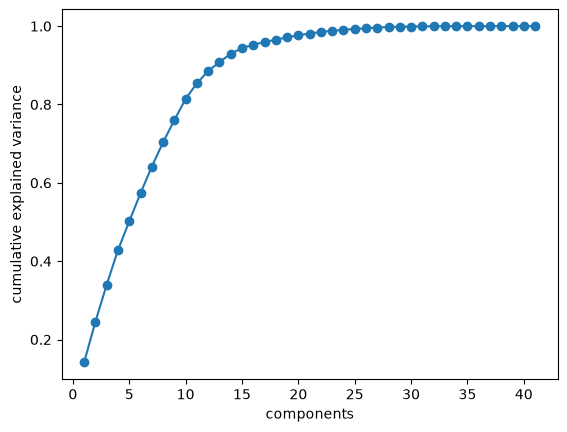

In [18]:
X_demo = prep.transform(train_set)
centered = X_demo - X_demo.mean(axis=0)
_, singular, _ = np.linalg.svd(centered, full_matrices=False)
explained = np.cumsum(singular**2) / np.sum(singular**2)
print(
    X_demo.shape[1],
    "features; components for 90% / 95% of the variance:",
    int(np.searchsorted(explained, 0.90) + 1),
    "/",
    int(np.searchsorted(explained, 0.95) + 1),
)
plt.plot(range(1, len(explained) + 1), explained, marker="o")
plt.xlabel("components")
plt.ylabel("cumulative explained variance")
plt.show()

**Insights.** PCA is only used to inspect redundancy. With about 40 features the dimensionality is small, so no reduction is applied and all models use the full matrix.

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
print(pd.Series(y_train).value_counts(normalize=True).round(3).to_dict())

{0: 0.672, 1: 0.328}


**Insights.** About one third of the bookings are canceled. Classes are balanced with inverse-frequency class weights, and the decision threshold is tuned for Macro F1 instead of using 0.5.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
X_train, X_val = prep.transform(train_set), prep.transform(val_set)
T_train, T_val = prep.transform_tree(train_set), prep.transform_tree(val_set)
print(
    "model matrix:",
    X_train.shape,
    "| tree matrix (gaps kept as NaN, categories as codes):",
    T_train.shape,
)

model matrix: (21847, 41) | tree matrix (gaps kept as NaN, categories as codes): (21847, 17)


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
prep = Preprocessor().fit(train_set)
X_train, X_val = prep.transform(train_set), prep.transform(val_set)
T_train, T_val = prep.transform_tree(train_set), prep.transform_tree(val_set)
assert not np.isnan(X_train).any()
assert not np.isnan(X_val).any()

results = []


def evaluate(name, variant, proba):
    threshold, f1 = best_threshold(y_val, proba, CFG.GRID)
    default = macro_f1(y_val, (proba >= 0.5).astype(np.int64))
    results.append(
        {
            "model": name,
            "variant": variant,
            "macro_f1": round(f1, 4),
            "threshold": round(threshold, 2),
            "macro_f1@0.5": round(default, 4),
        }
    )
    return f1


print("pipeline ready:", X_train.shape, X_val.shape)

pipeline ready: (21847, 41) (5462, 41)


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [22]:
knn_scores = {
    k: evaluate("KNN", f"k={k}", KNN(k).fit(X_train, y_train).predict_proba(X_val))
    for k in (5, 15, 31, 61)
}
best_k = max(knn_scores, key=knn_scores.get)
print({k: round(v, 4) for k, v in knn_scores.items()}, "-> best k =", best_k)

{5: 0.7936, 15: 0.8067, 31: 0.808, 61: 0.8031} -> best k = 31


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [23]:
tree_scores = {}
for depth, leaf in [(6, 40), (8, 20), (10, 20), (14, 20), (14, 40)]:
    tree = DecisionTree(depth, 2 * leaf, leaf, class_weight="balanced").fit(
        T_train, y_train, prep.tree_categorical_mask_
    )
    tree_scores[(depth, leaf)] = evaluate(
        "Decision Tree (CART)", f"depth={depth}, leaf={leaf}", tree.predict_proba(T_val)
    )
best_tree = max(tree_scores, key=tree_scores.get)
print(
    {k: round(v, 4) for k, v in tree_scores.items()},
    "-> best (depth, min leaf) =",
    best_tree,
)

{(6, 40): 0.7896, (8, 20): 0.805, (10, 20): 0.8077, (14, 20): 0.8085, (14, 40): 0.7998} -> best (depth, min leaf) = (14, 20)


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

l1 0.7614 | zero weights: 5 | final objective: 0.491
l2 0.7611 | zero weights: 1 | final objective: 0.4904
elasticnet 0.7614 | zero weights: 4 | final objective: 0.4907


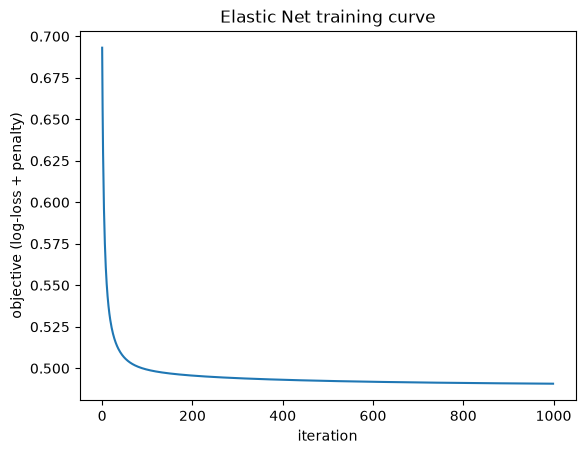

In [24]:
for penalty in ("l1", "l2", "elasticnet"):
    model = LogisticRegression(penalty, alpha=1e-4, class_weight="balanced").fit(
        X_train, y_train
    )
    f1 = evaluate("Logistic Regression", penalty, model.predict_proba(X_val))
    print(
        penalty,
        round(f1, 4),
        "| zero weights:",
        int((model.coef_ == 0).sum()),
        "| final objective:",
        round(model.loss_history_[-1], 4),
    )
plt.plot(model.loss_history_)
plt.xlabel("iteration")
plt.ylabel("objective (log-loss + penalty)")
plt.title("Elastic Net training curve")
plt.show()

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [25]:
for kernel in ("linear", "poly", "rbf"):
    svm = SVM(kernel, C=1.0).fit(X_train, y_train)
    f1 = evaluate("SVM", kernel, svm.predict_proba(X_val))
    print(
        kernel,
        round(f1, 4),
        "| support vectors:",
        len(svm.dual_coef_),
        "| SMO iterations:",
        svm.n_iter_,
    )

linear 0.7629 | support vectors: 3357 | SMO iterations: 48450
poly 0.7817 | support vectors: 2921 | SMO iterations: 21451
rbf 0.782 | support vectors: 3247 | SMO iterations: 5707


## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [26]:
nb = NaiveBayes().fit(X_train, y_train, prep.numeric_mask_)
print(
    round(evaluate("Naive Bayes", "Gaussian + Bernoulli", nb.predict_proba(X_val)), 4)
)

0.6464


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

,model,variant,macro_f1,threshold,macro_f1@0.5
0,Decision Tree (CART),"depth=14, leaf=20",0.8085,0.71,0.7960
1,KNN,k=31,0.8080,0.46,0.8057
2,SVM,rbf,0.7820,0.57,0.7677
3,Logistic Regression,l1,0.7614,0.63,0.7308
4,Naive Bayes,Gaussian + Bernoulli,0.6464,0.95,0.4914


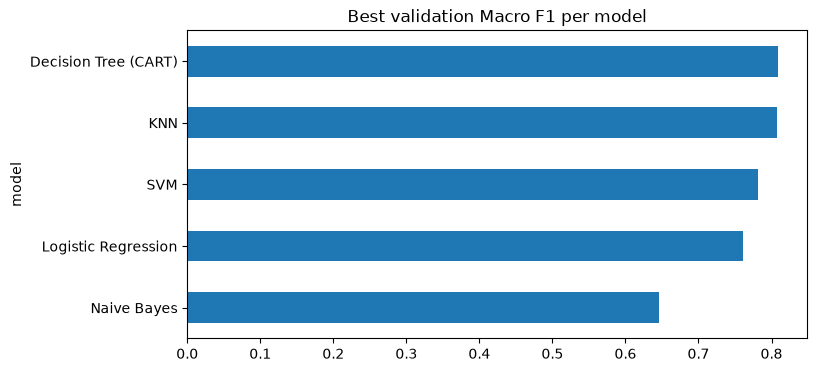

In [27]:
table = pd.DataFrame(results)
best_per_model = table.loc[table.groupby("model")["macro_f1"].idxmax()].sort_values(
    "macro_f1", ascending=False
)
display(best_per_model.reset_index(drop=True))
best_per_model.plot.barh(
    x="model",
    y="macro_f1",
    legend=False,
    figsize=(8, 4),
    title="Best validation Macro F1 per model",
)
plt.gca().invert_yaxis()
plt.show()

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [28]:
def oof_proba(name, frame, y, n_splits=5):
    proba = np.zeros(len(y))
    for fold_train, fold_test in stratified_kfold(y, n_splits, CFG.SEED):
        fold_prep = Preprocessor().fit(frame.iloc[fold_train])
        if name == "tree":
            model = DecisionTree(
                best_tree[0], 2 * best_tree[1], best_tree[1], class_weight="balanced"
            )
            model.fit(
                fold_prep.transform_tree(frame.iloc[fold_train]),
                y[fold_train],
                fold_prep.tree_categorical_mask_,
            )
            proba[fold_test] = model.predict_proba(
                fold_prep.transform_tree(frame.iloc[fold_test])
            )
        else:
            model = KNN(best_k).fit(
                fold_prep.transform(frame.iloc[fold_train]), y[fold_train]
            )
            proba[fold_test] = model.predict_proba(
                fold_prep.transform(frame.iloc[fold_test])
            )
    return proba


cv = {}
for name in ("tree", "knn"):
    proba = oof_proba(name, train_clean, y_all)
    threshold, f1 = best_threshold(y_all, proba, CFG.GRID)
    cv[name] = {"proba": proba, "threshold": threshold, "macro_f1": f1}
    print(f"{name}: out-of-fold Macro F1 = {f1:.4f} at threshold {threshold:.2f}")
final_name = max(cv, key=lambda n: cv[n]["macro_f1"])
print("final model:", final_name)

tree: out-of-fold Macro F1 = 0.8088 at threshold 0.66
knn: out-of-fold Macro F1 = 0.8096 at threshold 0.47
final model: knn


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

          algorithm              variant implementation  macro_f1  threshold  accuracy  seconds  label_agreement
                KNN                 k=31        scratch    0.8080       0.46    0.8316      5.0              NaN
                KNN                 k=31   scikit-learn    0.8080       0.46    0.8316      0.9           1.0000
      Decision Tree          CART (gini)        scratch    0.8085       0.71    0.8382      1.1              NaN
      Decision Tree          CART (gini)   scikit-learn    0.8216       0.61    0.8396      0.2           0.8880
Logistic Regression                   L1        scratch    0.7614       0.63    0.7917      3.9              NaN
Logistic Regression                   L1   scikit-learn    0.7629       0.61    0.7902     20.0           0.9806
Logistic Regression                   L2        scratch    0.7611       0.62    0.7898      3.9              NaN
Logistic Regression                   L2   scikit-learn    0.7635       0.63    0.7935      4.2 

,algorithm,variant,implementation,macro_f1,threshold,accuracy,seconds,label_agreement
0,KNN,k=31,scratch,0.8080,0.46,0.8316,5.0,NaN
1,KNN,k=31,scikit-learn,0.8080,0.46,0.8316,0.9,1.0000
2,Decision Tree,CART (gini),scratch,0.8085,0.71,0.8382,1.1,NaN
3,Decision Tree,CART (gini),scikit-learn,0.8216,0.61,0.8396,0.2,0.8880
4,Logistic Regression,L1,scratch,0.7614,0.63,0.7917,3.9,NaN
5,Logistic Regression,L1,scikit-learn,0.7629,0.61,0.7902,20.0,0.9806
6,Logistic Regression,L2,scratch,0.7611,0.62,0.7898,3.9,NaN
7,Logistic Regression,L2,scikit-learn,0.7635,0.63,0.7935,4.2,0.9861
8,Logistic Regression,Elastic Net,scratch,0.7614,0.63,0.7917,3.5,NaN
9,Logistic Regression,Elastic Net,scikit-learn,0.7629,0.61,0.7902,6.3,0.9802


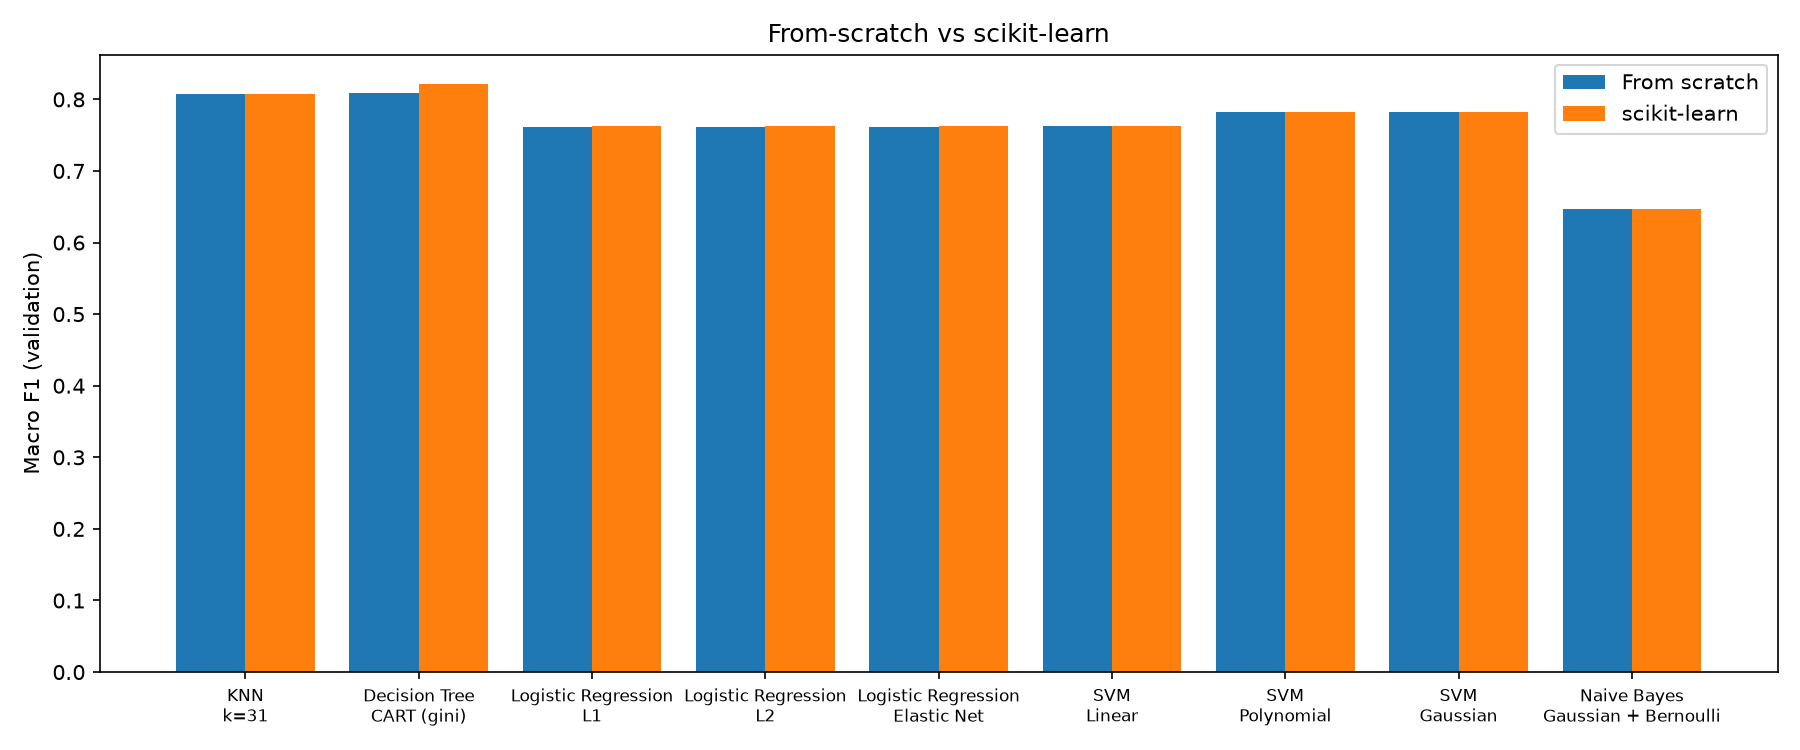

In [29]:
runpy.run_path(str(CFG.ROOT / "src" / "compare_models.py"), run_name="__main__")
plt.switch_backend("module://matplotlib_inline.backend_inline")
comparison = pd.read_csv(CFG.OUTPUT_DIR / "results.csv")
display(comparison)
display(Image(filename=str(CFG.OUTPUT_DIR / "model_comparison.png")))

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [30]:
models = {
    "knn": KNN(best_k).fit(X_train, y_train),
    "decision_tree": DecisionTree(
        best_tree[0], 2 * best_tree[1], best_tree[1], class_weight="balanced"
    ).fit(T_train, y_train, prep.tree_categorical_mask_),
    "logistic_regression": LogisticRegression(
        "elasticnet", alpha=1e-4, class_weight="balanced"
    ).fit(X_train, y_train),
    "svm_gaussian": SVM("rbf").fit(X_train, y_train),
    "naive_bayes": NaiveBayes().fit(X_train, y_train, prep.numeric_mask_),
}
inputs = {"decision_tree": T_val}
(CFG.OUTPUT_DIR / "models").mkdir(exist_ok=True)
for name, model in models.items():
    path = CFG.OUTPUT_DIR / "models" / f"{name}.pkl"
    model.save(path)
    loaded = type(model).load(path)
    x = inputs.get(name, X_val)
    assert np.allclose(model.predict_proba(x), loaded.predict_proba(x))
    print(
        f"{name}: saved ({path.stat().st_size / 1024:.0f} KB) and reloaded, predictions identical"
    )

knn: saved (7340 KB) and reloaded, predictions identical
decision_tree: saved (37 KB) and reloaded, predictions identical
logistic_regression: saved (10 KB) and reloaded, predictions identical
svm_gaussian: saved (1113 KB) and reloaded, predictions identical
naive_bayes: saved (1 KB) and reloaded, predictions identical


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [31]:
prep_full = Preprocessor().fit(train_clean)
if final_name == "tree":
    final_model = DecisionTree(
        best_tree[0], 2 * best_tree[1], best_tree[1], class_weight="balanced"
    )
    final_model.fit(
        prep_full.transform_tree(train_clean), y_all, prep_full.tree_categorical_mask_
    )
    test_proba = final_model.predict_proba(prep_full.transform_tree(test_df))
else:
    final_model = KNN(best_k).fit(prep_full.transform(train_clean), y_all)
    test_proba = final_model.predict_proba(prep_full.transform(test_df))
labels = (test_proba >= cv[final_name]["threshold"]).astype(np.int64)
submission = pd.DataFrame({"id": test_df["id"], "is_canceled": labels})
submission.to_csv(CFG.OUTPUT_DIR / "submission.csv", index=False)
print(
    final_name,
    "| rows:",
    len(submission),
    "| predicted canceled share:",
    round(labels.mean(), 3),
)
display(submission.head())

knn | rows: 6844 | predicted canceled share: 0.318


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [32]:
pred = (cv[final_name]["proba"] >= cv[final_name]["threshold"]).astype(np.int64)
print(confusion_matrix(y_all, pred))
errors = train_clean.assign(error=(pred != y_all))
display(errors.groupby("booking_channel")["error"].agg(["mean", "size"]).round(3))
lead = pd.cut(errors["days_before_arrival"], [-1, 7, 30, 90, 180, 400])
display(
    errors.groupby(lead, observed=True)["error"].mean().round(3).to_frame("error rate")
)

[[16187  2178]
 [ 2377  6567]]


,mean,size
booking_channel,,
Airline,0.193,88
Complimentary,0.007,300
Corporate,0.083,1512
Offline Agent,0.113,7902
Online Travel Agent,0.201,17507


,error rate
days_before_arrival,
"(-1, 7]",0.083
"(7, 30]",0.140
"(30, 90]",0.179
"(90, 180]",0.246
"(180, 400]",0.139


**Insights.** *To be written by the group after reading the tables above: which kinds of bookings are misclassified most often, and why.*